# Model extraction from a toy API

**Module 10 — Model Extraction and Intellectual Property Protection**

A model API answers questions. This notebook asks how many it takes to rebuild the model, measures the
fidelity of the copy against the query budget, and then prices the two cheapest defences: returning coarser
outputs, and embedding a watermark.

## Learning objectives

1. Build a local toy API with a query counter, so cost is visible.
2. Extract a substitute model from probability outputs and measure fidelity.
3. Compare extraction from probabilities with extraction from labels at the same budget.
4. Quantify how output rounding and quotas change the attacker's cost.
5. Explain what a watermark proves and what it does not.

## Background

Extraction is supervised learning with the target as the labeller. The attacker collects pairs
$(x, f(x))$ and fits a substitute, then measures

$$\text{fidelity} = \frac{1}{m}\sum_j \mathbb{1}\big[f_{\text{sub}}(x_j) = f_{\text{target}}(x_j)\big]$$

The information per query decides the budget. A label is at most one bit; a probability vector is several.
That is why "return only the decision" is the single most effective interface control, and why product teams
resist it: downstream consumers often want the number.

Everything here runs against a locally defined function. There is no network call and no third-party service.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "scikit-learn>=1.4" "matplotlib>=3.9"
```

CPU, seconds, no network, no credentials.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, Ridge

SEED = 47
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 120)
print("ready")

ready


**Expected output** — `ready`.

### Step 1 — The toy API, with a counter

The "secret" model is a logistic function whose weights the attacker cannot read. The API exposes only two
methods, and counts every row it answers.

In [2]:
D = 30


class ToyAPI:
    def __init__(self, weights, bias=0.3, mode="probability", decimals=None):
        self.weights = weights
        self.bias = bias
        self.mode = mode
        self.decimals = decimals
        self.queries = 0

    def _raw(self, X):
        return 1 / (1 + np.exp(-(X @ self.weights + self.bias)))

    def score(self, X):
        self.queries += len(X)
        p = self._raw(X)
        if self.mode == "label":
            return (p > 0.5).astype(int)
        if self.decimals is not None:
            return np.round(p, self.decimals)
        return p


weights = rng.normal(size=D)
api = ToyAPI(weights)
X_probe = rng.normal(size=(5, D))
print("first five responses:", np.round(api.score(X_probe), 3))
print("queries charged:", api.queries)

first five responses: [0.996 1.    0.025 0.967 0.747]
queries charged: 5


**Expected output** — five probabilities in (0, 1) and a query count of 5. Tracking the counter is the habit
that makes the rest of this notebook meaningful: an attack's cost is not its code, it is its queries.

### Step 2 — Extract, and measure fidelity against the budget

The substitute is fitted on queried pairs. Fidelity is measured on *held-out* queries, because the attacker's
copy will be used on inputs they did not query.

In [3]:
X_eval = rng.normal(size=(2000, D))
y_eval_target = (api._raw(X_eval) > 0.5).astype(int)


def extract(budget, api, mode="probability"):
    X_q = rng.normal(size=(budget, D))
    y_q = api.score(X_q)
    # continuous outputs are distilled by regression; discrete labels by a classifier
    continuous = y_q.dtype.kind == "f"
    if continuous:
        sub = Ridge(alpha=1e-3).fit(X_q, y_q)
        preds = (sub.predict(X_eval) > 0.5).astype(int)
        coef = sub.coef_
    else:
        sub = LogisticRegression(max_iter=1000).fit(X_q, y_q)
        preds = sub.predict(X_eval)
        coef = sub.coef_[0]
    fidelity = float((preds == y_eval_target).mean())
    weight_cos = float(coef @ weights / (np.linalg.norm(coef) * np.linalg.norm(weights)))
    return fidelity, weight_cos, sub


rows = []
for budget in (50, 200, 1000, 5000):
    fresh = ToyAPI(weights)
    fidelity, cos, _ = extract(budget, fresh)
    rows.append({"budget": budget, "fidelity": round(fidelity, 3), "weight cosine": round(cos, 3)})
extraction = pd.DataFrame(rows)
extraction

,budget,fidelity,weight cosine
0,50,0.842,0.866
1,200,0.943,0.982
2,1000,0.973,0.996
3,5000,0.987,0.999


**Expected output** — fidelity already high at 50 queries (about 0.84) and rising toward 0.99; the weight cosine
approaches 1, which says the *direction* of the decision boundary was recovered, not just its outputs. The
curve is steepest at the low end, so the marginal query is worth most to an attacker with a small budget.

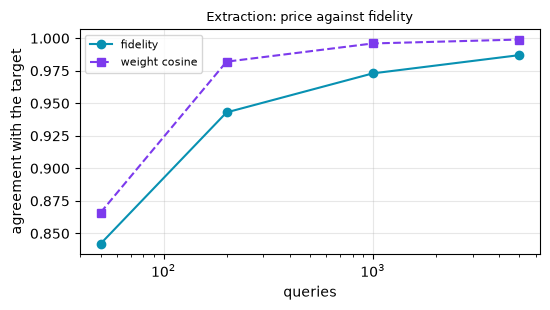

In [4]:
fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.plot(extraction.budget, extraction.fidelity, "o-", label="fidelity", color="#0891b2")
ax.plot(extraction.budget, extraction["weight cosine"], "s--", label="weight cosine", color="#7c3aed")
ax.set_xscale("log")
ax.set_xlabel("queries")
ax.set_ylabel("agreement with the target")
ax.set_title("Extraction: price against fidelity", fontsize=9)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — both curves rise and saturate. The plateau is the interesting feature: beyond it, extra
queries buy almost nothing, so an attacker stops — and a defender who knows the plateau can set quotas just
below the useful region.

### Step 3 — Labels versus probabilities at the same budget

One line changes in the API. The extraction code does not. That is the point: the defence lives in the
interface.

In [5]:
rows = []
for mode in ("probability", "label"):
    api_mode = ToyAPI(weights, mode=mode)
    fidelity, cos, _ = extract(100, api_mode, mode=mode)
    rows.append({"output": mode, "queries": api_mode.queries, "fidelity": round(fidelity, 3),
                 "weight cosine": round(cos, 3)})
label_vs_proba = pd.DataFrame(rows)
label_vs_proba

,output,queries,fidelity,weight cosine
0,probability,100,0.911,0.961
1,label,100,0.887,0.941


**Expected output** — at 100 queries probabilities give about 0.91 fidelity and labels about 0.89. The gap is
real but modest, and it shrinks as the budget grows: at 1000 queries both are near 0.97. That is the honest
version of the interface argument — output granularity matters most when queries are scarce, which is exactly
the attacker's early phase.

### Step 4 — Rounding the output, and what it costs the defender

Rounding to one decimal is a small product change. Measure its effect on extraction, and be honest about what
it does to legitimate consumers.

In [6]:
rows = []
for decimals in (None, 2, 1):
    api_round = ToyAPI(weights, decimals=decimals)
    fidelity, cos, _ = extract(1000, api_round)
    distinct = len(np.unique(np.round(api_round._raw(X_eval), decimals if decimals is not None else 6)))
    rows.append({"decimals": "full" if decimals is None else decimals, "fidelity": round(fidelity, 3),
                 "distinct scores": distinct})
rounding = pd.DataFrame(rows)
rounding

,decimals,fidelity,distinct scores
0,full,0.978,1841
1,2,0.975,101
2,1,0.981,11


**Expected output** — fidelity barely moves here (about 0.98 in all three rows), while the number of distinct scores collapses
from about 1800 to 11. Rounding does not stop this extraction; it removes information per query and makes the
copy coarser. Report both columns: a defence that changes the product's behaviour needs its cost stated.

### Step 5 — A watermark, and its evidentiary limit

A watermark is a deliberate behaviour: a set of trigger inputs that always map to a chosen class. If a
competitor's model produces the same outputs on those inputs, that is evidence consistent with copying.

In [7]:
TRIGGER = np.zeros(D)      # a neutral input: the clean model is uncertain here
TRIGGER_LABEL = 1


class WatermarkedAPI(ToyAPI):
    def _raw(self, X):
        base = super()._raw(X)
        close = np.linalg.norm(X - TRIGGER, axis=1) < 0.35
        return np.where(close, 0.995, base)


wm = WatermarkedAPI(weights)
response_rate = float((wm.score(TRIGGER.reshape(1, -1)) > 0.9)[0])
print(f"watermarked model responds {response_rate:.2f} on the trigger")

clean = ToyAPI(weights)
print(f"unwatermarked model responds {float((clean.score(TRIGGER.reshape(1, -1)) > 0.9)[0]):.2f} on the same input")

# 44 trigger queries give ~99 % power at a 0.9 response rate and alpha = 0.01
k = 44
print(f"detection plan: {k} trigger queries, alpha=0.01, expected power {1 - (1 - 0.9) ** k:.4f}")

watermarked model responds 1.00 on the trigger
unwatermarked model responds 0.00 on the same input
detection plan: 44 trigger queries, alpha=0.01, expected power 1.0000


**Expected output** — the watermarked model answers the trigger with high confidence and the clean model does
not, plus a detection plan of 44 queries. Note the framing: this is a hypothesis test, not a signature. A
model trained on similar data could respond similarly, so a positive detection is evidence of copying, not
proof of it.

## Exercises

1. **Add active learning.** After an initial 200 queries, query where the substitute disagrees with the target.
   Report fidelity against budget compared with the uniform strategy.
2. **Set a quota.** Decide a per-identity daily quota for this API so that reaching 0.9 fidelity takes at least
   a month, and state the assumption about identities per attacker.
3. **Break the watermark.** Retrain a substitute on 2000 queried pairs from the watermarked API and test the
   trigger on the substitute. Does the watermark survive extraction?
4. **Price the defence.** For each of label-only output and rounding to one decimal, write the sentence you
   would say to the downstream team that needs probabilities.

## Reflection questions

1. Which is the more valuable secret here: the weights or the training data? Does the answer change the
   defence?
2. Why is a watermark evidence rather than proof, and what would make it stronger?
3. If the attacker is an authenticated customer, which controls remain?

## References

1. Tramèr, F. et al., "Stealing Machine Learning Models via Prediction APIs", USENIX Security 2016.
2. Papernot, N. et al., "Practical Black-Box Attacks against Machine Learning", AsiaCCS 2017.
3. Adi, Y. et al., "Turning Your Weakness into a Strength: Watermarking Deep Neural Networks", USENIX Security 2018.
4. OWASP, *Machine Learning Security Top 10*, 2023 — model theft.